In [ ]:
import sys

!{sys.executable} -m pip install -U pandas matplotlib tqdm pyyaml opencv-python-headless ultralytics albumentations


   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   -------- ------------------------------- 2.1/9.7 MB 13.2 MB/s eta 0:00:01
   ------------ --------------------------- 3.1/9.7 MB 8.2 MB/s eta 0:00:01
   ---------------- ----------------------- 3.9/9.7 MB 7.2 MB/s eta 0:00:01
   -------------------- ------------------- 5.0/9.7 MB 6.5 MB/s eta 0:00:01
   ------------------------ --------------- 6.0/9.7 MB 6.2 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.7 MB 5.9 MB/s eta 0:00:01
   --------------------------------- ------ 8.1/9.7 MB 5.8 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.7 MB 5.7 MB/s eta 0:00:01
   ---------------------------------------  9.7/9.7 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 5.1 MB/s  0:00:01


In [ ]:
# CELL 2 — Imports & Configuration


In [ ]:
import os
import shutil
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm

import torch

from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\Shadab\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
print("CUDA Available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

print("Torch Version :", torch.__version__)


CUDA Available : True
GPU : NVIDIA GeForce RTX 3060 Ti
Torch Version : 2.11.0+cu128


In [ ]:
#DATASET PATHS

DATASET_DIR = "./datasets/gwhd_2021"

IMAGE_DIR = os.path.join(
    DATASET_DIR,
    "images"
)

TRAIN_CSV = os.path.join(
    DATASET_DIR,
    "competition_train.csv"
)

VAL_CSV = os.path.join(
    DATASET_DIR,
    "competition_val.csv"
)

TEST_CSV = os.path.join(
    DATASET_DIR,
    "competition_test.csv"
)

In [ ]:
#OUTPUT DIRECTORIES

WORK_DIR = "./gwhd_yolo"

YOLO_DIR = os.path.join(
    WORK_DIR,
    "yolo_dataset"
)

RUNS_DIR = os.path.join(
    WORK_DIR,
    "runs"
)

FINAL_MODEL_DIR = os.path.join(
    WORK_DIR,
    "final_model"
)

for d in [
    YOLO_DIR,
    RUNS_DIR,
    FINAL_MODEL_DIR
]:
    os.makedirs(d, exist_ok=True)

print("Directories Created")



Directories Created


In [ ]:
#TRAINING SETTINGS

EPOCHS = 100
BATCH_SIZE = 4
IMG_SIZE = 1024
CONF_THRESHOLD = 0.25

In [ ]:
import os

print(os.listdir("./datasets"))

for root, dirs, files in os.walk("./datasets"):

    print("\nROOT:", root)

    print("DIRS:", dirs[:5])

    print("FILES:", files[:5])

['.ipynb_checkpoints', 'gwhd_2021.zip']

ROOT: ./datasets
DIRS: ['.ipynb_checkpoints']
FILES: ['gwhd_2021.zip']

ROOT: ./datasets\.ipynb_checkpoints
DIRS: []
FILES: []


In [ ]:
#Extract Dataset

import zipfile
import os

# ZIP FILE LOCATION
zip_path = "./datasets/gwhd_2021.zip"

# WHERE TO EXTRACT
extract_path = "./datasets/gwhd_2021"

# CREATE FOLDER
os.makedirs(extract_path, exist_ok=True)

# EXTRACT ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully")


Dataset Extracted Successfully


In [ ]:
import os

print(os.listdir("./datasets/gwhd_2021"))

['gwhd_2021']


In [ ]:
# Dataset Paths & Configuration

DATASET_DIR = "./datasets/gwhd_2021/gwhd_2021"

# Folder containing all wheat field images
IMAGE_DIR = os.path.join(
    DATASET_DIR,
    "images"
)

# CSV annotation files
TRAIN_CSV = os.path.join(
    DATASET_DIR,
    "competition_train.csv"
)

VAL_CSV = os.path.join(
    DATASET_DIR,
    "competition_val.csv"
)

TEST_CSV = os.path.join(
    DATASET_DIR,
    "competition_test.csv"
)

print("Dataset paths configured successfully.")

Dataset paths configured successfully.


In [ ]:
# Create Output Directories

# This folder contains converted YOLO dataset
YOLO_DIR = "./gwhd_yolo_dataset"

# YOLO training results will be stored here
RUNS_DIR = "./runs"

FINAL_MODEL_DIR = "./final_model"

# Create folders if they do not exist
for d in [
    YOLO_DIR,
    RUNS_DIR,
    FINAL_MODEL_DIR
]:
    os.makedirs(d, exist_ok=True)

print("Output folders created.")

Output folders created.


In [ ]:
#Training Settings

EPOCHS = 100
BATCH_SIZE = 4
IMG_SIZE = 1024
CONF_THRESHOLD = 0.25

print("Training configuration loaded")

Training configuration loaded


In [ ]:
# CELL 7 — Load CSV Files

import pandas as pd

df_train = pd.read_csv(TRAIN_CSV)

df_val = pd.read_csv(VAL_CSV)

df_test = pd.read_csv(TEST_CSV)

print("Train Images :", len(df_train))
print("Validation Images :", len(df_val))
print("Test Images :", len(df_test))

print("\nSample Row:\n")

print(df_train.iloc[0])

Train Images : 3657
Validation Images : 1476
Test Images : 1382

Sample Row:

image_name     4563856cc6d75c670eafd86d5eb7245fbe8f273c28f9e3...
BoxesString    99 692 160 764;641 27 697 115;935 978 1012 102...
domain                                                 Arvalis_1
Name: 0, dtype: str


In [ ]:

# Parse Bounding Boxes

def parse_boxes(box_string):

    # Some images may have no annotations
    if pd.isna(box_string):
        return []

    s = str(box_string).strip()
    if s == "" or s.lower() == "no_box":
        return []
    boxes = []

    # Multiple boxes are separated by ;
    for entry in s.split(";"):

        parts = entry.strip().split()

        if len(parts) == 4:

            boxes.append(
                list(map(int, parts))
            )

    return boxes


# Quick test
sample_boxes = parse_boxes(
    df_train.iloc[0]["BoxesString"]
)

print("Parsed Boxes :", len(sample_boxes))
print("First Box :", sample_boxes[0])

Parsed Boxes : 41
First Box : [99, 692, 160, 764]


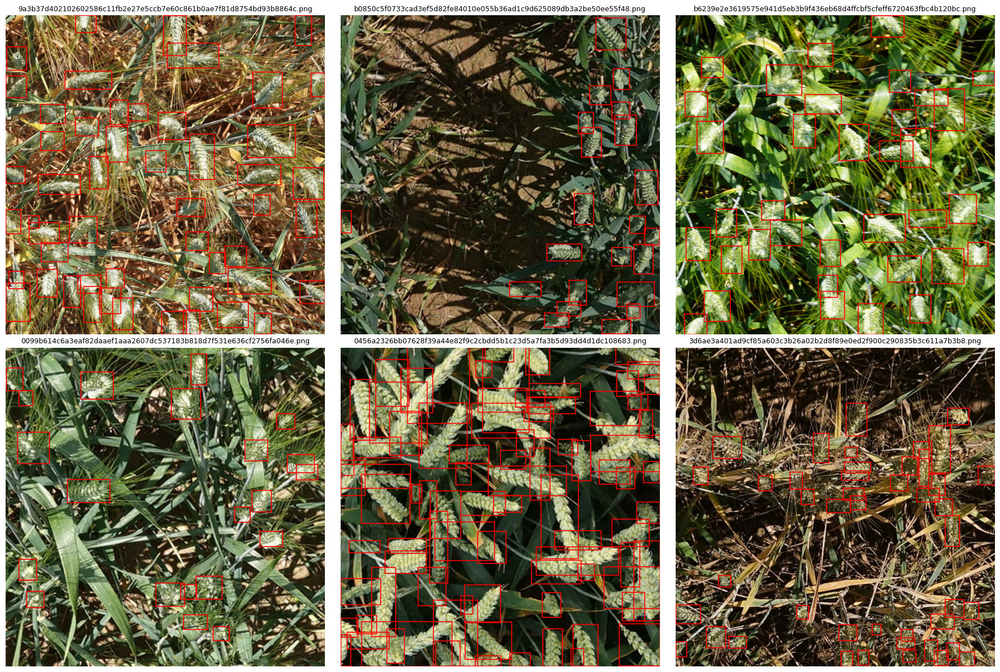

In [ ]:

# Visualize Dataset Samples

import cv2
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 12)
)

axes = axes.flatten()

# Random samples
samples = df_train.sample(
    6,
    random_state=42
)

for idx, (_, row) in enumerate(samples.iterrows()):

    img_path = os.path.join(
        IMAGE_DIR,
        row["image_name"]
    )

    img = cv2.imread(img_path)

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    boxes = parse_boxes(
        row["BoxesString"]
    )

    # Draw bounding boxes
    for x1, y1, x2, y2 in boxes:

        cv2.rectangle(
            img,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

    axes[idx].imshow(img)

    axes[idx].set_title(
        row["image_name"],
        fontsize=9
    )

    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#  Convert Dataset to YOLO Format

import shutil
from tqdm import tqdm

def to_yolo(boxes, img_w=1024, img_h=1024):

    labels = []
    for x1, y1, x2, y2 in boxes:

        # Convert box format
        cx = ((x1 + x2) / 2) / img_w
        cy = ((y1 + y2) / 2) / img_h

        bw = (x2 - x1) / img_w
        bh = (y2 - y1) / img_h

        labels.append(
            f"0 {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}"
        )

    return labels

def prepare_split(df, split):

    img_out = os.path.join(
        YOLO_DIR,
        "images",
        split
    )

    lbl_out = os.path.join(
        YOLO_DIR,
        "labels",
        split
    )

    os.makedirs(img_out, exist_ok=True)
    os.makedirs(lbl_out, exist_ok=True)

    for _, row in tqdm(
        df.iterrows(),
        total=len(df),
        desc=split
    ):

        src_img = os.path.join(
            IMAGE_DIR,
            row["image_name"]
        )

        dst_img = os.path.join(
            img_out,
            row["image_name"]
        )

        # Copy image
        if not os.path.exists(dst_img):

            shutil.copy2(
                src_img,
                dst_img
            )

        # Create label file
        labels = to_yolo(
            parse_boxes(
                row["BoxesString"]
            )
        )

        label_name = (
            os.path.splitext(
                row["image_name"]
            )[0]
            + ".txt"
        )

        with open(
            os.path.join(
                lbl_out,
                label_name
            ),
            "w"
        ) as f:

            f.write("\n".join(labels))

# Prepare train and validation splits
prepare_split(df_train, "train")
prepare_split(df_val, "val")
print("YOLO dataset created")

val: 100%|██████████| 1476/1476 [00:30<00:00, 48.07it/s]

YOLO dataset created


In [ ]:

# Create YAML Config

import yaml

yaml_path = os.path.join(
    YOLO_DIR,
    "gwhd.yaml" )

yaml_data = {
    "path": YOLO_DIR,
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": ["wheat_head"] }

with open(yaml_path, "w") as f:

    yaml.dump(
        yaml_data,
        f )

print(open(yaml_path).read())

names:
- wheat_head
nc: 1
path: ./gwhd_yolo_dataset
train: images/train
val: images/val



In [ ]:
# Load YOLOv9

from ultralytics import YOLO
model = YOLO("yolov9c.pt")
print("YOLOv9 model loaded successfully")

YOLOv9 model loaded successfully


In [ ]:

# Train YOLOv9

model.train(

    data=yaml_path,
    epochs=100,
    batch=BATCH_SIZE,
    imgsz=IMG_SIZE,
    device=0,
    workers=4,
    optimizer="AdamW",

    # Learning rate settings
    lr0=0.0005,
    lrf=0.01,

    # Regularization
    weight_decay=0.0005,
    warmup_epochs=5,
    patience=20,
    cos_lr=True,

    # Data augmentation
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=10,
    translate=0.1,
    scale=0.5,
    shear=2,
    fliplr=0.5,
    flipud=0.2,
    mosaic=1.0,
    mixup=0.1,
    # Helps reduce overfitting
    dropout=0.1,

    # Save settings
    project=RUNS_DIR,

    name="yolov9_wheat_stage1",
    exist_ok=True,
    save=True,
    save_period=10,
    val=True,
    plots=True,
    verbose=True
)

print("Training finished")

Ultralytics 8.4.48  Python-3.13.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060 Ti, 8191MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=./gwhd_yolo_dataset\gwhd.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.1, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.2, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov9c.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov9_wheat_stage1, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, over

In [ ]:
#######################stage 2

In [ ]:

import sys

!{sys.executable} -m pip install segment-anything
!{sys.executable} -m pip install opencv-python
!{sys.executable} -m pip install matplotlib
!{sys.executable} -m pip install tqdm
!{sys.executable} -m pip install scikit-image

print("Libraries installed")

Libraries installed


In [ ]:
# IMPORTS

import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.utils.data import random_split

from segment_anything import sam_model_registry

print("Imports loaded")

Imports loaded


In [ ]:
# PATHS

BASE_DIR = r"C:\Users\Shadab\Documents\New project"

GWFSS_DIR = os.path.join(
    BASE_DIR,
    "datasets",
    "GWFSS_v1.0",
    "GWFSS_v1.0_labelled"
)

IMAGE_DIR = os.path.join(GWFSS_DIR, "images")
MASK_DIR  = os.path.join(GWFSS_DIR, "masks")

CHECKPOINT_DIR = os.path.join(BASE_DIR, "stage2_checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("IMAGE_DIR:", IMAGE_DIR)
print("MASK_DIR :", MASK_DIR)

IMAGE_DIR: C:\Users\Shadab\Documents\New project\datasets\GWFSS_v1.0\GWFSS_v1.0_labelled\images
MASK_DIR : C:\Users\Shadab\Documents\New project\datasets\GWFSS_v1.0\GWFSS_v1.0_labelled\masks


In [ ]:
# SETTINGS

DEVICE         = "cuda" if torch.cuda.is_available() else "cpu"
SAM_MODEL_TYPE = "vit_h"
SAM_CHECKPOINT = "./sam_vit_h_4b8939.pth"
BATCH_SIZE     = 1
EPOCHS         = 30
LEARNING_RATE  = 1e-7
WEIGHT_DECAY   = 1e-5
IMAGE_SIZE     = 1024
SAM_MASK_SIZE  = 256   # SAM always outputs 256x256 low-res masks
NUM_WORKERS    = 0

print("DEVICE:", DEVICE)

DEVICE: cuda


In [ ]:
sam = sam_model_registry[SAM_MODEL_TYPE](checkpoint=SAM_CHECKPOINT)
sam.to(DEVICE)

print("SAM loaded")

SAM loaded


In [ ]:
#FREEZE IMAGE ENCODER ONLY

# Freeze image encoder — we do NOT train this
for param in sam.image_encoder.parameters():
    param.requires_grad = False

# Unfreeze prompt encoder
for param in sam.prompt_encoder.parameters():
    param.requires_grad = True

# Unfreeze mask decoder
for param in sam.mask_decoder.parameters():
    param.requires_grad = True

# Count trainable parameters
trainable = sum(
    p.numel() for p in sam.parameters() if p.requires_grad
)

total = sum(
    p.numel() for p in sam.parameters()
)

print(f"Trainable parameters : {trainable:,}")
print(f"Total parameters     : {total:,}")
print(f"Frozen               : {total - trainable:,}")

Trainable parameters : 4,064,560
Total parameters     : 641,090,608
Frozen               : 637,026,048


In [ ]:
# LOSS FUNCTIONS

class DiceLoss(nn.Module):

    def __init__(self):
        super().__init__()

    def forward(self, pred, target, smooth=1):

        pred   = torch.sigmoid(pred).view(-1)
        target = target.view(-1)

        intersection = (pred * target).sum()

        dice = (
            2 * intersection + smooth
        ) / (
            pred.sum() + target.sum() + smooth
        )

        return 1 - dice


class FocalLoss(nn.Module):

    def __init__(self, alpha=0.8, gamma=2):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, pred, target):

        bce   = F.binary_cross_entropy_with_logits(
            pred, target, reduction='none'
        )
        pt    = torch.exp(-bce)
        focal = self.alpha * (1 - pt) ** self.gamma * bce

        return focal.mean()


class IoULoss(nn.Module):

    def __init__(self):
        super().__init__()

    def forward(self, pred, target):

        pred = torch.sigmoid(pred)

        intersection = (pred * target).sum()
        union        = (pred + target - pred * target).sum()
        iou          = (intersection + 1e-6) / (union + 1e-6)

        return 1 - iou


print("Loss functions ready: DiceLoss | FocalLoss | IoULoss")

Loss functions ready: DiceLoss | FocalLoss | IoULoss


In [ ]:
# EVALUATION METRICS

def compute_dice(pred, target):

    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()

    intersection = (pred * target).sum()
    union        = pred.sum() + target.sum()
    dice         = (2 * intersection + 1e-6) / (union + 1e-6)

    return dice.item()


def compute_iou(pred, target):

    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()

    intersection = (pred * target).sum()
    union        = (pred + target).clamp(0, 1).sum()
    iou          = (intersection + 1e-6) / (union + 1e-6)

    return iou.item()


print("Metrics ready: compute_dice | compute_iou")

Metrics ready: compute_dice | compute_iou


In [ ]:
# ERROR-AWARE BOX PERTURBATION

def compute_box_iou(boxA, boxB):
    """Compute IoU between two boxes [x1,y1,x2,y2]"""

    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    interArea = max(0, xB - xA) * max(0, yB - yA)

    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    iou = interArea / float(
        boxAArea + boxBArea - interArea + 1e-6
    )

    return iou


def perturb_box(box, img_w, img_h, prob=0.8):
    """
    Apply random perturbation to a bounding box.
    prob   = 0.8  → 80% chance of perturbation (WheatSAM best config)
    shift  = ±20  → random pixel shift
    scale  = ±20% → random size change
    overlap > 0.1 → perturbed box must still overlap original
    """

    if random.random() > prob:
        return box

    x1, y1, x2, y2 = box
    original_box    = [x1, y1, x2, y2]

    for _ in range(10):

        shift_x = random.randint(-20, 20)
        shift_y = random.randint(-20, 20)
        scale   = random.uniform(0.8, 1.2)   # ±20%

        w  = x2 - x1
        h  = y2 - y1
        cx = (x1 + x2) / 2
        cy = (y1 + y2) / 2

        w  *= scale
        h  *= scale
        cx += shift_x
        cy += shift_y

        nx1 = int(max(0,     cx - w / 2))
        ny1 = int(max(0,     cy - h / 2))
        nx2 = int(min(img_w, cx + w / 2))
        ny2 = int(min(img_h, cy + h / 2))

        new_box = [nx1, ny1, nx2, ny2]

        # Only accept if perturbed box still overlaps original
        if compute_box_iou(original_box, new_box) > 0.1:
            return new_box

    return original_box


print("Error-aware perturbation ready")

Error-aware perturbation ready


In [ ]:
# DATASET

class WheatDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir   = image_dir
        self.mask_dir    = mask_dir
        self.image_paths = []

        for root, dirs, files in os.walk(image_dir):
            for file in files:
                if file.endswith(".png"):
                    self.image_paths.append(
                        os.path.join(root, file)
                    )

        self.image_paths = sorted(self.image_paths)

        print(f"Found {len(self.image_paths)} images")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image_path    = self.image_paths[idx]
        relative_path = os.path.relpath(image_path, self.image_dir)
        mask_path     = os.path.join(self.mask_dir, relative_path)

        # IMAGE- Load and resize to 1024x1024 for SAM input
        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMAGE_SIZE, IMAGE_SIZE))

        # MASK-Resize to 256x256 to match SAM low-res output size
        mask = cv2.imread(mask_path, 0)
        mask = cv2.resize(
            mask,
            (SAM_MASK_SIZE, SAM_MASK_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        binary_mask = (mask > 0).astype(np.uint8)

        #BOUNDING BOXES - Extract one box per connected wheat head region
        num_labels, labels_im = cv2.connectedComponents(binary_mask)

        boxes = []

        for label in range(1, num_labels):

            ys, xs = np.where(labels_im == label)

            if len(xs) == 0:
                continue

            x1 = xs.min()
            y1 = ys.min()
            x2 = xs.max()
            y2 = ys.max()

            # Scale boxes: 256x256 mask space → 1024x1024 image space
            scale_x = IMAGE_SIZE / SAM_MASK_SIZE   # = 4.0
            scale_y = IMAGE_SIZE / SAM_MASK_SIZE   # = 4.0

            x1 = int(x1 * scale_x)
            x2 = int(x2 * scale_x)
            y1 = int(y1 * scale_y)
            y2 = int(y2 * scale_y)

            # error-aware perturbation
            box = perturb_box([x1, y1, x2, y2], IMAGE_SIZE, IMAGE_SIZE)
            boxes.append(box)

        boxes = np.array(boxes, dtype=np.float32)

        return (image, binary_mask, boxes)


print("WheatDataset class defined")

WheatDataset class defined


In [ ]:
# DATALOADER

dataset = WheatDataset(IMAGE_DIR, MASK_DIR)

train_size = int(0.8 * len(dataset))
val_size   = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print(f"Total dataset : {len(dataset)}")
print(f"Train size    : {len(train_dataset)}")
print(f"Val size      : {len(val_dataset)}")

Found 1096 images
Total dataset : 1096
Train size    : 876
Val size      : 220


In [ ]:
# OPTIMIZER and LOSS FUNCTIONS

optimizer = torch.optim.AdamW(
    list(sam.mask_decoder.parameters()) +
    list(sam.prompt_encoder.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

dice_loss_fn  = DiceLoss()
focal_loss_fn = FocalLoss()
iou_loss_fn   = IoULoss()

print("Optimizer : AdamW")
print("LR        :", LEARNING_RATE)
print("Losses    : Dice + Focal + IoU")

Optimizer : AdamW
LR        : 1e-07
Losses    : Dice + Focal + IoU


In [ ]:
# TRAINING + VALIDATION LOOP

torch.cuda.empty_cache()

scaler = torch.amp.GradScaler("cuda")

best_val_dice = 0.0

history = {
    "train_loss" : [],
    "val_loss"   : [],
    "val_dice"   : [],
    "val_iou"    : []
}

for epoch in range(EPOCHS):

    # TRAINING

    sam.train()

    train_loss = 0.0
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]")

    for image, gt_mask, boxes in loop:

        image   = image[0].numpy()
        gt_mask = gt_mask.float().to(DEVICE)
        boxes   = boxes[0].float().to(DEVICE)

        # Skip if no boxes found in this image
        if boxes.numel() == 0:
            continue

        image_tensor = torch.tensor(image).permute(2,0,1).float().unsqueeze(0).to(DEVICE)

        optimizer.zero_grad()

        with torch.amp.autocast("cuda"):

            # STEP 1 — Image Encoder (frozen, no grad)
            with torch.no_grad():
                image_embedding = sam.image_encoder(
                    sam.preprocess(image_tensor)
                )

            # STEP 2 — Prompt Encoder (boxes as prompts)
            sparse_embeddings, dense_embeddings = sam.prompt_encoder(
                points=None,
                boxes=boxes,
                masks=None
            )

            # STEP 3 — Mask Decoder (predicts segmentation)
            low_res_masks, _ = sam.mask_decoder(
                image_embeddings=image_embedding,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse_embeddings,
                dense_prompt_embeddings=dense_embeddings,
                multimask_output=False
            )

            # Combine all predicted masks → single wheat mask
            # Shape: [1, 1, 256, 256]
            pred_mask = low_res_masks.max(dim=0, keepdim=True)[0]

            # gt_mask_4d shape: [1, 1, 256, 256]
            gt_mask_4d = gt_mask.unsqueeze(1)

            # Verify shapes match before computing loss
            assert pred_mask.shape == gt_mask_4d.shape, \
                f"Shape mismatch: pred={pred_mask.shape} gt={gt_mask_4d.shape}"

            # Compute combined loss
            loss_dice  = dice_loss_fn(pred_mask, gt_mask_4d)
            loss_focal = focal_loss_fn(pred_mask, gt_mask_4d)
            loss_iou   = iou_loss_fn(pred_mask, gt_mask_4d)
            loss       = loss_dice + loss_focal + loss_iou

        # Backpropagation
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        loop.set_postfix(loss=f"{loss.item():.4f}")

    train_loss /= len(train_loader)

    # VALIDATION

    sam.eval()

    val_loss  = 0.0
    val_dice  = 0.0
    val_iou   = 0.0
    val_count = 0

    with torch.no_grad():

        for image, gt_mask, boxes in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]"):

            image   = image[0].numpy()
            gt_mask = gt_mask.float().to(DEVICE)
            boxes   = boxes[0].float().to(DEVICE)

            if boxes.numel() == 0:
                continue

            image_tensor = torch.tensor(image).permute(2,0,1).float().unsqueeze(0).to(DEVICE)

            image_embedding = sam.image_encoder(
                sam.preprocess(image_tensor)
            )

            sparse_embeddings, dense_embeddings = sam.prompt_encoder(
                points=None,
                boxes=boxes,
                masks=None
            )

            low_res_masks, _ = sam.mask_decoder(
                image_embeddings=image_embedding,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse_embeddings,
                dense_prompt_embeddings=dense_embeddings,
                multimask_output=False
            )

            pred_mask  = low_res_masks.max(dim=0, keepdim=True)[0]
            gt_mask_4d = gt_mask.unsqueeze(1)

            loss_dice  = dice_loss_fn(pred_mask, gt_mask_4d)
            loss_focal = focal_loss_fn(pred_mask, gt_mask_4d)
            loss_iou   = iou_loss_fn(pred_mask, gt_mask_4d)
            loss       = loss_dice + loss_focal + loss_iou

            val_loss += loss.item()
            val_dice += compute_dice(pred_mask, gt_mask_4d)
            val_iou  += compute_iou(pred_mask, gt_mask_4d)
            val_count += 1

    val_loss /= max(val_count, 1)
    val_dice /= max(val_count, 1)
    val_iou  /= max(val_count, 1)

    # Save to history
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)
    history["val_iou"].append(val_iou)

    print(f"\n{'='*55}")
    print(f"  Epoch      : {epoch+1}/{EPOCHS}")
    print(f"  Train Loss : {train_loss:.4f}")
    print(f"  Val Loss   : {val_loss:.4f}")
    print(f"  Val Dice   : {val_dice:.4f}")
    print(f"  Val mIoU   : {val_iou:.4f}")
    print(f"{'='*55}")

    # Save best model based on Val Dice
    if val_dice > best_val_dice:

        best_val_dice   = val_dice
        best_model_path = os.path.join(
            CHECKPOINT_DIR,
            "best_sam_stage2.pth"
        )

        torch.save(sam.state_dict(), best_model_path)

        print(f"  ✓ Best model saved → Val Dice: {best_val_dice:.4f}")

print("\n" + "="*55)
print("Training completed")
print(f"Best Val Dice : {best_val_dice:.4f}")
print("="*55)

Epoch 1/30 [Val]: 100%|██████████████████████████████████████████████████████████████| 220/220 [04:13<00:00,  1.15s/it]



  Epoch      : 1/30
  Train Loss : 1.1233
  Val Loss   : 1.0602
  Val Dice   : 0.7572
  Val mIoU   : 0.6405
  ✓ Best model saved → Val Dice: 0.7572


Epoch 2/30 [Val]: 100%|██████████████████████████████████████████████████████████████| 220/220 [04:12<00:00,  1.15s/it]



  Epoch      : 2/30
  Train Loss : 1.0465
  Val Loss   : 0.9930
  Val Dice   : 0.7643
  Val mIoU   : 0.6515
  ✓ Best model saved → Val Dice: 0.7643


Epoch 3/30 [Val]: 100%|██████████████████████████████████████████████████████████████| 220/220 [04:13<00:00,  1.15s/it]


...


  Epoch      : 28/30
  Train Loss : 0.5826
  Val Loss   : 0.5804
  Val Dice   : 0.8741
  Val mIoU   : 0.7910
  ✓ Best model saved → Val Dice: 0.8741


Epoch 29/30 [Val]: 100%|█████████████████████████████████████████████████████████████| 220/220 [04:12<00:00,  1.15s/it]



  Epoch      : 29/30
  Train Loss : 0.5847
  Val Loss   : 0.5701
  Val Dice   : 0.8750
  Val mIoU   : 0.7927
  ✓ Best model saved → Val Dice: 0.8750


Epoch 30/30 [Val]: 100%|█████████████████████████████████████████████████████████████| 220/220 [04:12<00:00,  1.15s/it]



  Epoch      : 30/30
  Train Loss : 0.5809
  Val Loss   : 0.5749
  Val Dice   : 0.8753
  Val mIoU   : 0.7924
  ✓ Best model saved → Val Dice: 0.8753

Training completed
Best Val Dice : 0.8753


In [ ]:

# Clean evaluation — no box perturbation

sam.load_state_dict(
    torch.load(
        os.path.join(CHECKPOINT_DIR, "best_sam_stage2.pth")
    )
)

sam.eval()

clean_dataset = WheatDataset(IMAGE_DIR, MASK_DIR)

# Temporarily disable perturbation for clean eval
original_getitem = clean_dataset.__getitem__

eval_dice  = 0.0
eval_iou   = 0.0
eval_count = 0

with torch.no_grad():

    for idx in tqdm(range(len(clean_dataset)), desc="Clean Evaluation"):

        image, gt_mask, boxes = clean_dataset[idx]

        # Re-extract clean boxes from mask
        mask_path = os.path.join(
            MASK_DIR,
            os.path.relpath(
                clean_dataset.image_paths[idx],
                IMAGE_DIR
            )
        )

        mask = cv2.imread(mask_path, 0)
        mask = cv2.resize(mask, (SAM_MASK_SIZE, SAM_MASK_SIZE), interpolation=cv2.INTER_NEAREST)
        binary_mask = (mask > 0).astype(np.uint8)

        num_labels, labels_im = cv2.connectedComponents(binary_mask)
        clean_boxes = []

        for label in range(1, num_labels):
            ys, xs = np.where(labels_im == label)
            if len(xs) == 0:
                continue
            x1 = int(xs.min() * (IMAGE_SIZE / SAM_MASK_SIZE))
            x2 = int(xs.max() * (IMAGE_SIZE / SAM_MASK_SIZE))
            y1 = int(ys.min() * (IMAGE_SIZE / SAM_MASK_SIZE))
            y2 = int(ys.max() * (IMAGE_SIZE / SAM_MASK_SIZE))
            clean_boxes.append([x1, y1, x2, y2])

        if len(clean_boxes) == 0:
            continue

        clean_boxes  = torch.tensor(clean_boxes, dtype=torch.float32).to(DEVICE)
        gt_mask_t    = torch.tensor(binary_mask, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(DEVICE)
        image_tensor = torch.tensor(image).permute(2,0,1).float().unsqueeze(0).to(DEVICE)

        image_embedding = sam.image_encoder(sam.preprocess(image_tensor))

        sparse_embeddings, dense_embeddings = sam.prompt_encoder(
            points=None,
            boxes=clean_boxes,
            masks=None
        )

        low_res_masks, _ = sam.mask_decoder(
            image_embeddings=image_embedding,
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_embeddings,
            dense_prompt_embeddings=dense_embeddings,
            multimask_output=False
        )

        pred_mask = low_res_masks.max(dim=0, keepdim=True)[0]

        eval_dice  += compute_dice(pred_mask, gt_mask_t)
        eval_iou   += compute_iou(pred_mask, gt_mask_t)
        eval_count += 1

eval_dice /= eval_count
eval_iou  /= eval_count

print(f"\n{'='*55}")
print(f"  CLEAN EVALUATION RESULTS")
print(f"  Dice Score : {eval_dice:.4f}  ({eval_dice*100:.2f}%)")
print(f"  mIoU       : {eval_iou:.4f}  ({eval_iou*100:.2f}%)")
print(f"  Images     : {eval_count}")
print(f"{'='*55}")

Found 1096 images


Clean Evaluation: 100%|████████████████████████████████████████████████████████████| 1096/1096 [20:56<00:00,  1.15s/it]


  CLEAN EVALUATION RESULTS
  Dice Score : 0.8761  (87.61%)
  mIoU       : 0.7956  (79.56%)
  Images     : 1080


In [ ]:
#stage3

In [ ]:
# INSTALL LIBRARIES

import sys

!{sys.executable} -m pip install timm albumentations scikit-learn seaborn

print("Libraries installed")

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 2.6/2.6 MB 20.0 MB/s  0:00:00
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   ---------------------------------------  7.9/8.0 MB 66.8 MB/s eta 0:00:01
   ---------------------------------------- 8.0/8.0 MB 32.1 MB/s  0:00:00
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

   ------------- -------------------------- 2/6 [joblib]
   ------------- -------------------------- 2/6 [joblib]
   ------------- -------------------------- 2/6 [joblib]
   ------------- -------------------------- 2/6 [joblib]
   ------------- -------------------------- 2/6 [joblib]
   ------------- -------------------------- 2/6 [joblib]
   -------------------- ------------------- 3/6 [scikit-learn]
   -------------------- ------------------- 3/6 [scikit-learn]
   -------------------- ------------------- 3/6 [

In [ ]:
# libraries

import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
from collections import Counter

# PyTorch libraries
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from torchvision import transforms

import timm

# Dataset splitting and evaluation metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score
)

print("Imports done")

Imports done


In [ ]:

zip_path = os.path.join(
    BASE_DIR,
    "datasets",
    "Wheat Disease.zip"
)

os.makedirs(DISEASE_DIR, exist_ok=True)

print(f"Extracting: {zip_path}")
print(f"Target    : {DISEASE_DIR}")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(DISEASE_DIR)

print("\nExtraction complete!")
print("\nContents:")

for item in sorted(os.listdir(DISEASE_DIR)):
    full_path = os.path.join(DISEASE_DIR, item)
    if os.path.isdir(full_path):
        count = len(os.listdir(full_path))
        print(f"  [FOLDER] {item}  ({count} files)")
    else:
        print(f"  [FILE]   {item}")

Extracting: C:\Users\Shadab\Documents\New project\datasets\Wheat Disease.zip
Target    : C:\Users\Shadab\Documents\New project\datasets\bangladesh_wheat_disease

Extraction complete!

Contents:
  [FOLDER] Wheat Disease  (4 files)


In [ ]:
# Paths and settings
BASE_DIR = r"C:\Users\Shadab\Documents\New project"

DATA_DIR = os.path.join(
    BASE_DIR, "datasets", "bangladesh_wheat_disease",
    "Wheat Disease", "Original Dataset"
)

SAVE_DIR = os.path.join(BASE_DIR, "stage3_checkpoints")
os.makedirs(SAVE_DIR, exist_ok=True)

DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 32
EPOCHS     = 30
LR         = 1e-4
IMG_SIZE   = 224
LAMBDA     = 0.5
PATIENCE   = 7

print("Device:", DEVICE)

Device: cuda


In [ ]:
# Label mapping
LABEL_MAP = {
    "HealthyLeaf":     {"disease": 0, "severity": -1},
    "BlackPoint":      {"disease": 1, "severity": 0},     # mild
    "FusariumFootRot": {"disease": 2, "severity": 1},     # moderate
    "LeafBlight":      {"disease": 3, "severity": 1},     # moderate
    "WheatBlast":      {"disease": 4, "severity": 2},     # severe
}

DISEASE_NAMES  = ["Healthy", "BlackPoint", "Fusarium", "LeafBlight", "WheatBlast"]
SEVERITY_NAMES = ["Mild", "Moderate", "Severe"]

In [ ]:
# Load all images and labels
all_images   = []
all_disease  = []
all_severity = []

for cls in sorted(os.listdir(DATA_DIR)):
    cls_path = os.path.join(DATA_DIR, cls)
    if not os.path.isdir(cls_path) or cls not in LABEL_MAP:
        continue
    lab = LABEL_MAP[cls]
    for f in sorted(os.listdir(cls_path)):
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_images.append(os.path.join(cls_path, f))
            all_disease.append(lab["disease"])
            all_severity.append(lab["severity"])

print(f"Total: {len(all_images)} images")
print(f"Disease : {Counter(all_disease)}")
print(f"Severity: {Counter(all_severity)}")

Total: 1603 images
Disease : Counter({3: 400, 4: 400, 1: 303, 2: 250, 0: 250})
Severity: Counter({1: 650, 2: 400, 0: 303, -1: 250})


In [ ]:
# Dataset Splitting (70% Train, 15% Validation, 15% Test)

# First split: Train+Validation and Test
trainval_imgs, test_imgs, trainval_dis, test_dis, trainval_sev, test_sev = train_test_split(
    all_images, all_disease, all_severity,
    test_size=0.15, random_state=42, stratify=all_disease
)

# Second split: Train and Validation
train_imgs, val_imgs, train_dis, val_dis, train_sev, val_sev = train_test_split(
    trainval_imgs, trainval_dis, trainval_sev,
    test_size=0.176, random_state=42, stratify=trainval_dis
)

# Display split sizes
print(f"Train: {len(train_imgs)}  Val: {len(val_imgs)}  Test: {len(test_imgs)}")

Train: 1122  Val: 240  Test: 241


In [ ]:
# Transform — resize and normalize only
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [ ]:
# Dataset class
class WheatDiseaseDataset(Dataset):
    def __init__(self, paths, disease, severity, transform=None):
        self.paths    = paths
        self.disease  = disease
        self.severity = severity
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if self.transform:
            img = self.transform(img)

        d = torch.tensor(self.disease[idx], dtype=torch.long)
        s = self.severity[idx]
        s = torch.tensor(s if s >= 0 else 0, dtype=torch.long)
        return img, d, s

In [ ]:
# Dataloaders with class balancing

# Create datasets
train_data = WheatDiseaseDataset(train_imgs, train_dis, train_sev, transform)
val_data   = WheatDiseaseDataset(val_imgs, val_dis, val_sev, transform)
test_data  = WheatDiseaseDataset(test_imgs, test_dis, test_sev, transform)

# Compute class weights
counts  = Counter(train_dis)
weights = [1.0 / counts[d] for d in train_dis]

# Weighted sampler for balanced training
sampler = WeightedRandomSampler(weights, len(weights), replacement=True)

# Create dataloaders
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, sampler=sampler)
val_loader   = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train: {len(train_data)} ({len(train_loader)} batches)")
print(f"Val  : {len(val_data)} ({len(val_loader)} batches)")
print(f"Test : {len(test_data)} ({len(test_loader)} batches)")

Train: 1122 (36 batches)
Val  : 240 (8 batches)
Test : 241 (8 batches)


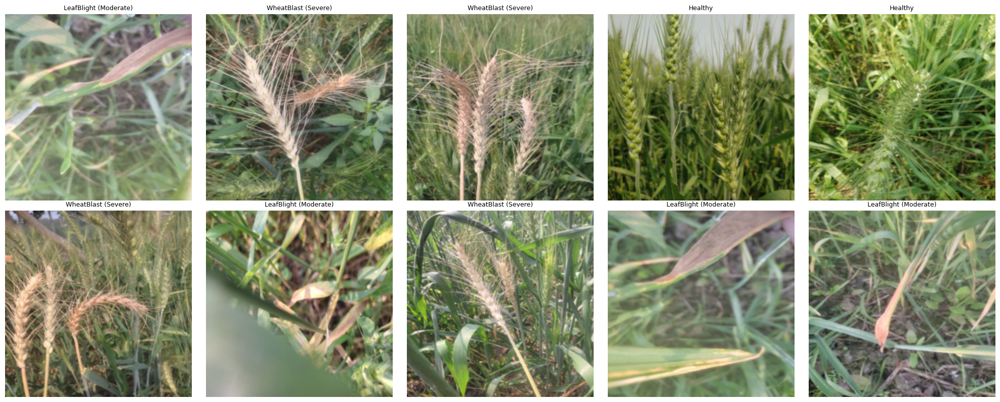

In [ ]:
# Visualize random training samples

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, idx in enumerate(random.sample(range(len(train_data)), 10)):

    # Get image and labels
    img, d, s = train_data[idx]

    # Convert tensor to displayable image
    img = img.permute(1,2,0).numpy() * [0.229,0.224,0.225] + [0.485,0.456,0.406]
    img = np.clip(img, 0, 1)

    # Create image label
    label = DISEASE_NAMES[d.item()]

    if d.item() > 0:
        label += f" ({SEVERITY_NAMES[s.item()]})"

    axes.flat[i].imshow(img)
    axes.flat[i].set_title(label, fontsize=9)
    axes.flat[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Multi-task model

class WheatDiseaseModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Pretrained EfficientNet-B0 backbone
        self.backbone = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0
        )

        feat = self.backbone.num_features

        # Disease classification head
        self.disease_head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(feat, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 5)
        )

        # Severity classification head
        self.severity_head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(feat, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 3)
        )

    def forward(self, x):

        feat = self.backbone(x)
        return self.disease_head(feat), self.severity_head(feat)

model = WheatDiseaseModel().to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 4,665,476


In [ ]:
# Loss and optimizer
disease_loss_fn  = nn.CrossEntropyLoss()
severity_loss_fn = nn.CrossEntropyLoss(reduction='none')

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5)

In [ ]:
# Model Training and Validation Loop

best_f1    = 0.0
no_improve = 0

# Store training history
history = {
    "train_loss": [],
    "val_loss": [],
    "disease_f1": [],
    "severity_f1": []
}

# Training epochs
for epoch in range(EPOCHS):

    # Training phase
    model.train()
    total_loss = 0

    for imgs, d_labels, s_labels in tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]"):

        # Move data to device
        imgs, d_labels, s_labels = imgs.to(DEVICE), d_labels.to(DEVICE), s_labels.to(DEVICE)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        d_out, s_out = model(imgs)

        # Disease classification loss
        loss_d = disease_loss_fn(d_out, d_labels)

        # Severity classification loss
        loss_s_all = severity_loss_fn(s_out, s_labels)

        # Apply severity loss only to diseased samples
        mask = (d_labels > 0).float()

        if mask.sum() > 0:
            loss_s = (loss_s_all * mask).sum() / mask.sum()
        else:
            loss_s = torch.tensor(0.0, device=DEVICE)

        # Combined loss
        loss = loss_d + LAMBDA * loss_s

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / len(train_loader)

    model.eval()

    val_loss = 0
    d_preds, d_true, s_preds, s_true = [], [], [], []

    with torch.no_grad():

        for imgs, d_labels, s_labels in val_loader:

            # Move data to device
            imgs, d_labels, s_labels = imgs.to(DEVICE), d_labels.to(DEVICE), s_labels.to(DEVICE)

            # Forward pass
            d_out, s_out = model(imgs)

            loss_d = disease_loss_fn(d_out, d_labels)

            loss_s_all = severity_loss_fn(s_out, s_labels)

            mask = (d_labels > 0).float()

            loss_s = (
                (loss_s_all * mask).sum() / mask.sum()
                if mask.sum() > 0
                else torch.tensor(0.0, device=DEVICE)
            )

            val_loss += (loss_d + LAMBDA * loss_s).item()

            # Disease predictions
            d_preds.extend(torch.argmax(d_out, 1).cpu().numpy())
            d_true.extend(d_labels.cpu().numpy())

            # Severity predictions for diseased samples
            sick = (d_labels > 0)

            if sick.sum() > 0:
                s_preds.extend(torch.argmax(s_out, 1)[sick].cpu().numpy())
                s_true.extend(s_labels[sick].cpu().numpy())

    val_loss /= len(val_loader)

    d_f1 = f1_score(d_true, d_preds, average='weighted')
    s_f1 = f1_score(s_true, s_preds, average='weighted') if s_true else 0.0
    d_acc = accuracy_score(d_true, d_preds)

    # Save metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["disease_f1"].append(d_f1)
    history["severity_f1"].append(s_f1)

    # Update learning rate
    scheduler.step(d_f1)
    print(f"\n  Loss: {train_loss:.4f}/{val_loss:.4f}  Acc: {d_acc*100:.1f}%  Disease F1: {d_f1:.4f}  Severity F1: {s_f1:.4f}")

    # Save best model
    if d_f1 > best_f1:

        best_f1 = d_f1
        no_improve = 0

        torch.save(
            model.state_dict(),
            os.path.join(SAVE_DIR, "best_disease_model.pth")
        )

        print(f"  Saved (F1: {best_f1:.4f})")

    else:
        no_improve += 1

    # Early stopping
    if no_improve >= PATIENCE:

        print(f"\n  Early stopping at epoch {epoch+1}")
        break

print(f"\nDone — Best F1: {best_f1:.4f}")

Epoch 1 [Train]: 100%|█████████████████████████████████████████████████████████████████| 36/36 [00:21<00:00,  1.66it/s]



  Loss: 1.5626/0.7197  Acc: 94.2%  Disease F1: 0.9381  Severity F1: 0.9901
  Saved (F1: 0.9381)


Epoch 2 [Train]: 100%|█████████████████████████████████████████████████████████████████| 36/36 [00:21<00:00,  1.65it/s]



  Loss: 0.4076/0.1628  Acc: 95.0%  Disease F1: 0.9482  Severity F1: 0.9901
  Saved (F1: 0.9482)


Epoch 3 [Train]: 100%|█████████████████████████████████████████████████████████████████| 36/36 [00:21<00:00,  1.64it/s]


...


  Loss: 0.0132/0.0445  Acc: 98.8%  Disease F1: 0.9875  Severity F1: 1.0000


Epoch 12 [Train]: 100%|████████████████████████████████████████████████████████████████| 36/36 [00:21<00:00,  1.66it/s]



  Loss: 0.0410/0.0609  Acc: 98.3%  Disease F1: 0.9833  Severity F1: 1.0000


Epoch 13 [Train]: 100%|████████████████████████████████████████████████████████████████| 36/36 [00:21<00:00,  1.66it/s]



  Loss: 0.0345/0.0559  Acc: 98.8%  Disease F1: 0.9875  Severity F1: 1.0000

  Early stopping at epoch 13

Done — Best F1: 0.9875


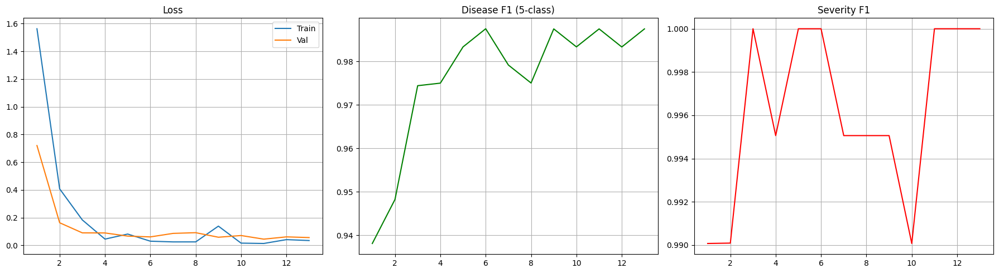

In [ ]:
# Plot training curves

ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Loss curve
ax[0].plot(ep, history["train_loss"], label="Train")
ax[0].plot(ep, history["val_loss"], label="Val")
ax[0].set_title("Loss")
ax[0].legend()
ax[0].grid(True)

# Disease F1 curve
ax[1].plot(ep, history["disease_f1"], color="green")
ax[1].set_title("Disease F1 (5-class)")
ax[1].grid(True)

# Severity F1 curve
ax[2].plot(ep, history["severity_f1"], color="red")
ax[2].set_title("Severity F1")
ax[2].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "training_curves.png"), dpi=150)
plt.show()

In [ ]:
# Test set evaluation
model.load_state_dict(torch.load(os.path.join(SAVE_DIR, "best_disease_model.pth")))
model.eval()

d_preds, d_true, s_preds, s_true = [], [], [], []

with torch.no_grad():
    for imgs, d_labels, s_labels in tqdm(test_loader, desc="Testing"):
        imgs, d_labels, s_labels = imgs.to(DEVICE), d_labels.to(DEVICE), s_labels.to(DEVICE)
        d_out, s_out = model(imgs)

        d_preds.extend(torch.argmax(d_out, 1).cpu().numpy())
        d_true.extend(d_labels.cpu().numpy())

        sick = (d_labels > 0)
        if sick.sum() > 0:
            s_preds.extend(torch.argmax(s_out, 1)[sick].cpu().numpy())
            s_true.extend(s_labels[sick].cpu().numpy())

# Disease results (5-class)
print("\n" + "=" * 50)
print("  5-CLASS DISEASE DETECTION — TEST")
print("=" * 50)
print(classification_report(d_true, d_preds, target_names=DISEASE_NAMES))

d_acc = accuracy_score(d_true, d_preds)
d_f1  = f1_score(d_true, d_preds, average='weighted')
print(f"  Accuracy: {d_acc*100:.2f}%")
print(f"  F1 Score: {d_f1:.4f}")

# Severity results
print("\n" + "=" * 50)
print("  SEVERITY GRADING — TEST")
print("=" * 50)
unique = sorted(set(s_true))
names  = [SEVERITY_NAMES[i] for i in unique]
print(classification_report(s_true, s_preds, target_names=names, labels=unique))

s_acc = accuracy_score(s_true, s_preds)
s_f1  = f1_score(s_true, s_preds, average='weighted')
print(f"  Accuracy: {s_acc*100:.2f}%")
print(f"  F1 Score: {s_f1:.4f}")

Testing: 100%|███████████████████████████████████████████████████████████████████████████| 8/8 [00:04<00:00,  1.90it/s]


  5-CLASS DISEASE DETECTION — TEST
              precision    recall  f1-score   support

     Healthy       0.97      1.00      0.99        38
  BlackPoint       1.00      0.98      0.99        45
    Fusarium       1.00      1.00      1.00        38
  LeafBlight       1.00      1.00      1.00        60
  WheatBlast       1.00      1.00      1.00        60

    accuracy                           1.00       241
   macro avg       0.99      1.00      1.00       241
weighted avg       1.00      1.00      1.00       241

  Accuracy: 99.59%
  F1 Score: 0.9959

  SEVERITY GRADING — TEST
              precision    recall  f1-score   support

        Mild       1.00      0.98      0.99        45
    Moderate       0.99      1.00      0.99        98
      Severe       1.00      1.00      1.00        60

    accuracy                           1.00       203
   macro avg       1.00      0.99      0.99       203
weighted avg       1.00      1.00      1.00       203

  Accuracy: 99.51%
  F1 Score

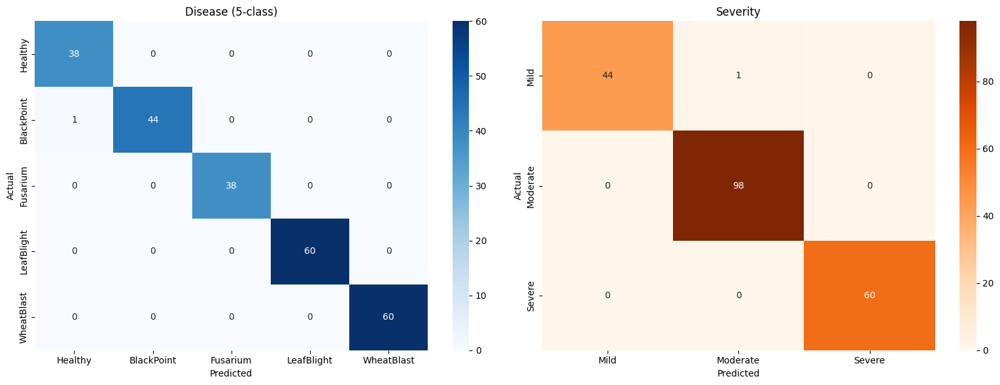

In [ ]:
# Plot confusion matrices

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Disease confusion matrix
cm1 = confusion_matrix(d_true, d_preds)

sns.heatmap(
    cm1,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=DISEASE_NAMES,
    yticklabels=DISEASE_NAMES,
    ax=ax[0]
)

ax[0].set_title("Disease (5-class)")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")

# Severity confusion matrix
unique = sorted(set(s_true))
names  = [SEVERITY_NAMES[i] for i in unique]

cm2 = confusion_matrix(s_true, s_preds, labels=unique)

sns.heatmap(
    cm2,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=names,
    yticklabels=names,
    ax=ax[1]
)

ax[1].set_title("Severity")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "confusion_matrices.png"), dpi=150)
plt.show()

In [ ]:
# Summary
print("=" * 50)
print("  STAGE 3 COMPLETE")
print(f"  Dataset : Original 1,603 images")
print(f"  Train: {len(train_imgs)}  Val: {len(val_imgs)}  Test: {len(test_imgs)}")
print(f"  Disease  (5-class) — Acc: {d_acc*100:.2f}%  F1: {d_f1:.4f}")
print(f"  Severity (3-class) — Acc: {s_acc*100:.2f}%  F1: {s_f1:.4f}")
print("=" * 50)

  STAGE 3 COMPLETE
  Dataset : Original 1,603 images
  Train: 1122  Val: 240  Test: 241
  Disease  (5-class) — Acc: 99.59%  F1: 0.9959
  Severity (3-class) — Acc: 99.51%  F1: 0.9951


In [ ]:

#FULL PIPELINE — Stage 1 + Stage 2 + Stage 3


In [ ]:
# Libraries
import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision import transforms
from ultralytics import YOLO
from segment_anything import sam_model_registry
import timm

print("Imports done")

Imports done


In [ ]:
# Project paths

BASE_DIR = r"C:\Users\Shadab\Documents\New project"

# Stage 1 weights
YOLO_WEIGHTS = os.path.join(BASE_DIR, "runs", "detect", "runs", "yolov9_wheat_stage1", "weights", "best.pt")

# Stage 2 weights
SAM_BASE = os.path.join(
    BASE_DIR,
    "sam_vit_h_4b8939.pth"
)

SAM_FINETUNED = os.path.join(
    BASE_DIR,
    "stage2_checkpoints",
    "best_sam_stage2.pth"
)

# Stage 3 weights
DISEASE_WEIGHTS = os.path.join(
    BASE_DIR,
    "stage3_checkpoints",
    "best_disease_model.pth"
)

# Output folder
OUTPUT_DIR = os.path.join(BASE_DIR, "pipeline_outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Device setup
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Verify model files
print("Checking model files:\n")

for name, path in [
    ("YOLOv9", YOLO_WEIGHTS),
    ("SAM base", SAM_BASE),
    ("SAM finetuned", SAM_FINETUNED),
    ("Disease model", DISEASE_WEIGHTS)
]:

    found = os.path.exists(path)

    print(f"  {name:15s}: {'Found' if found else 'NOT FOUND'}")

print(f"\nDevice: {DEVICE}")

Checking model files:

  YOLOv9         : Found
  SAM base       : Found
  SAM finetuned  : Found
  Disease model  : Found

Device: cuda


In [ ]:
# LOAD STAGE 1: YOLOv9

yolo = YOLO(YOLO_WEIGHTS)
print("Stage 1 — YOLOv9 loaded")

Stage 1 — YOLOv9 loaded


In [ ]:
# LOAD STAGE 2: SAM


sam = sam_model_registry["vit_h"](checkpoint=SAM_BASE)
sam.load_state_dict(torch.load(SAM_FINETUNED, map_location=DEVICE))
sam.to(DEVICE)
sam.eval()
print("Stage 2 — SAM loaded")

Stage 2 — SAM loaded


In [ ]:
# ── LOAD STAGE 3: DISEASE MODEL ──

class WheatDiseaseModel(nn.Module):
    def __init__(self):
        super().__init__()

        # Shared backbone
        self.backbone = timm.create_model("efficientnet_b0", pretrained=False, num_classes=0)
        feat = self.backbone.num_features    # 1280 features

        # Head 1
        self.disease_head = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(feat, 256), nn.ReLU(),
            nn.Dropout(0.2), nn.Linear(256, 5)
        )

        # Head 2
        self.severity_head = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(feat, 256), nn.ReLU(),
            nn.Dropout(0.2), nn.Linear(256, 3)
        )

    def forward(self, x):
        feat = self.backbone(x)
        return self.disease_head(feat), self.severity_head(feat)

# Create model and load trained weights
disease_model = WheatDiseaseModel()
disease_model.load_state_dict(torch.load(DISEASE_WEIGHTS, map_location=DEVICE))
disease_model.to(DEVICE)
disease_model.eval()
print("Stage 3 — Disease model loaded")

Stage 3 — Disease model loaded


In [ ]:
# LABELS AND COLORS

DISEASE_NAMES = ["Healthy", "BlackPoint", "Fusarium", "LeafBlight", "WheatBlast"]

SEVERITY_NAMES = ["Mild", "Moderate", "Severe"]

# visual map
COLORS = {
    0: (0, 255, 0),       # Healthy    = green
    1: (0, 255, 255),     # BlackPoint = yellow
    2: (0, 165, 255),     # Fusarium   = orange
    3: (0, 200, 200),     # LeafBlight = dark yellow
    4: (0, 0, 255),       # WheatBlast = red
}
# preprocessing used during Stage 3 training
disease_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

print("Labels, colors, and transforms ready")
print("All 3 models loaded successfully")

Labels, colors, and transforms ready
All 3 models loaded successfully


In [ ]:
# Pipeline Functions

# Stage 1: Wheat head detection
def detect_heads(image_path):

    # Run YOLOv9 inference
    results = yolo.predict(
        source=image_path,
        conf=0.25,
        iou=0.45,
        imgsz=1024,
        verbose=False
    )

    boxes = []

    for r in results:
        for box in r.boxes:

            # Extract box coordinates
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)

            boxes.append([x1, y1, x2, y2])

    return boxes


# Stage 2: Wheat head segmentation
def segment_heads(image, boxes):

    h, w = image.shape[:2]

    resized = cv2.resize(image, (1024, 1024))

    tensor = torch.tensor(resized).permute(2,0,1).float().unsqueeze(0).to(DEVICE)

    # Extract image embedding
    with torch.no_grad():
        embedding = sam.image_encoder(sam.preprocess(tensor))

    sx = 1024 / w
    sy = 1024 / h

    masks = []

    for box in boxes:

        x1, y1, x2, y2 = box

        # Scale bounding box
        scaled_box = [
            int(x1*sx),
            int(y1*sy),
            int(x2*sx),
            int(y2*sy)
        ]

        box_tensor = torch.tensor(
            [scaled_box],
            dtype=torch.float32
        ).to(DEVICE)

        # Generate segmentation mask
        with torch.no_grad():

            sparse, dense = sam.prompt_encoder(
                points=None,
                boxes=box_tensor,
                masks=None
            )

            low_res, _ = sam.mask_decoder(
                image_embeddings=embedding,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse,
                dense_prompt_embeddings=dense,
                multimask_output=False
            )

        # Convert to binary mask
        mask = torch.sigmoid(low_res[0, 0]).cpu().numpy()

        mask = (mask > 0.5).astype(np.uint8)

        # Resize mask to original size
        mask = cv2.resize(
            mask,
            (w, h),
            interpolation=cv2.INTER_NEAREST
        )

        masks.append(mask)

    return masks


# Stage 3: Disease classification
def classify_heads(image, boxes):

    diseases   = []
    severities = []

    for box in boxes:

        x1, y1, x2, y2 = box

        # Crop wheat head
        crop = image[y1:y2, x1:x2]

        # Skip empty crops
        if crop.size == 0:

            diseases.append(0)
            severities.append(-1)

            continue

        # Preprocess crop
        inp = disease_transform(crop).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            d_out, s_out = disease_model(inp)

        d = torch.argmax(d_out, 1).item()
        s = torch.argmax(s_out, 1).item()

        diseases.append(d)

        # Assign severity
        severities.append(s if d > 0 else -1)

    return diseases, severities


print("Pipeline functions ready")

Pipeline functions ready


In [ ]:
# Draw disease visualization

def draw_disease_map(image, boxes, masks, diseases, severities):

    output = image.copy()

    for box, mask, d, s in zip(boxes, masks, diseases, severities):

        x1, y1, x2, y2 = box

        # Select disease color
        color = COLORS.get(d, (0, 0, 255))

        label = DISEASE_NAMES[d]

        if d > 0 and 0 <= s <= 2:
            label += f" ({SEVERITY_NAMES[s]})"

        colored_mask = np.zeros_like(output)

        colored_mask[mask == 1] = color

        output = cv2.addWeighted(output, 1.0, colored_mask, 0.3, 0)

        # Draw bounding box
        cv2.rectangle(output, (x1, y1), (x2, y2), color, 2)

        text_size = cv2.getTextSize(
            label,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            1
        )[0]

        cv2.rectangle(
            output,
            (x1, y1 - text_size[1] - 6),
            (x1 + text_size[0] + 4, y1),
            color,
            -1
        )

        cv2.putText(
            output,
            label,
            (x1 + 2, y1 - 3),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            (0,0,0),
            1
        )

    return output

print("Drawing function ready")

Drawing function ready


Testing on: 0007634580386bd39d4d0d24df58893c3bb967e12d6fc065ce8659e9acacc928.png

Image size: (1024, 1024, 3)

Stage 1: Detecting wheat heads...
  Found 40 wheat heads

Stage 2: Segmenting each head...
  Created 40 masks

Stage 3: Classifying disease + severity...

  Results:
    Healthy: 8
    BlackPoint: 16
    Fusarium: 4
    LeafBlight: 11
    WheatBlast: 1


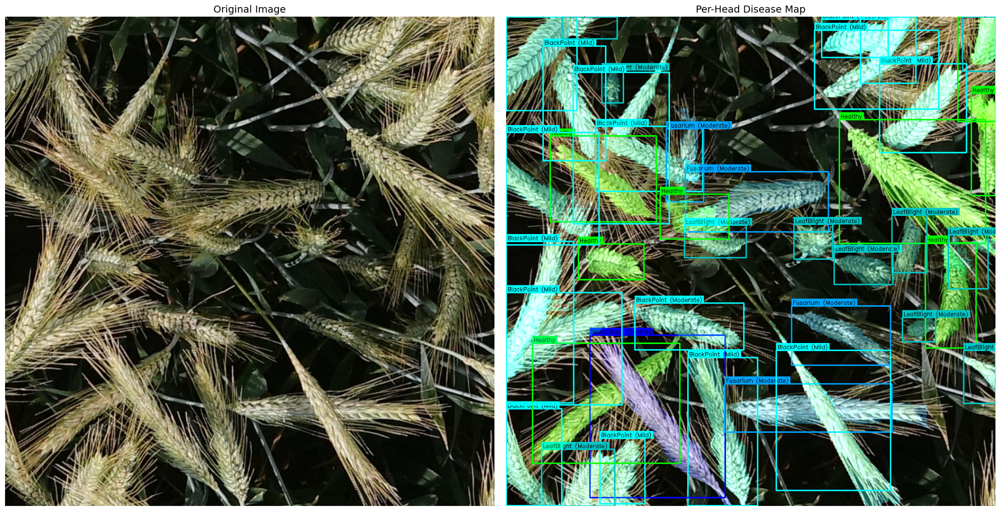


Saved to: C:\Users\Shadab\Documents\New project\pipeline_outputs


In [ ]:
# Run Pipeline on One Image

# Test image directory
IMAGE_DIR = os.path.join(
    BASE_DIR,
    "datasets",
    "gwhd_2021",
    "gwhd_2021",
    "images"
)

# Load image list
all_images = [
    f for f in os.listdir(IMAGE_DIR)
    if f.endswith(('.jpg', '.png'))
]

# Select test image
test_path = os.path.join(IMAGE_DIR, all_images[0])

print(f"Testing on: {os.path.basename(test_path)}\n")

image = cv2.imread(test_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
print(f"Image size: {image.shape}\n")

# Stage 1: Detection
print("Stage 1: Detecting wheat heads...")
boxes = detect_heads(test_path)
print(f"  Found {len(boxes)} wheat heads\n")

# Stage 2: Segmentation
print("Stage 2: Segmenting each head...")
masks = segment_heads(image, boxes)
print(f"  Created {len(masks)} masks\n")

# Stage 3: Classification
print("Stage 3: Classifying disease + severity...")
diseases, severities = classify_heads(image, boxes)
print("\n  Results:")

for i, name in enumerate(DISEASE_NAMES):
    count = sum(1 for d in diseases if d == i)
    if count > 0:
        print(f"    {name}: {count}")

# Generate disease map
result = draw_disease_map(
    image,
    boxes,
    masks,
    diseases,
    severities
)

# Display results
fig, ax = plt.subplots(1, 2, figsize=(20, 10))

ax[0].imshow(image)
ax[0].set_title("Original Image", fontsize=14)
ax[0].axis("off")

ax[1].imshow(result)
ax[1].set_title("Per-Head Disease Map", fontsize=14)
ax[1].axis("off")

# Save result
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "single_result.png"),
    dpi=150
)

plt.show()

print(f"\nSaved to: {OUTPUT_DIR}")

In [ ]:
# Run Pipeline on Random Images

sample = random.sample(all_images, min(10, len(all_images)))
print(f"Processing {len(sample)} images...\n")

all_results = []

for img_name in sample:

    img_path = os.path.join(IMAGE_DIR, img_name)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Stage 1: Detection
    boxes = detect_heads(img_path)
    # Stage 2: Segmentation
    masks = segment_heads(img, boxes)
    # Stage 3: Classification
    diseases, severities = classify_heads(img, boxes)

    # Count diseases
    counts = {}

    for i, name in enumerate(DISEASE_NAMES):
        counts[name] = sum(1 for d in diseases if d == i)

    # Save results
    all_results.append({
        "name": img_name,
        "heads": len(boxes),
        **counts
    })

    # Create disease map
    output = draw_disease_map(
        img,
        boxes,
        masks,
        diseases,
        severities
    )

    # Save output image
    save_path = os.path.join(
        OUTPUT_DIR,
        f"result_{img_name}"
    )

    cv2.imwrite(
        save_path,
        cv2.cvtColor(output, cv2.COLOR_RGB2BGR)
    )

    # Print image results
    print(f"  {img_name}")
    print(f"    Heads: {len(boxes)}")

    for name, count in counts.items():

        if count > 0:
            print(f"    {name}: {count}")

    print()
print(f"\n{'='*75}")
print(
    f"{'Image':35s} "
    f"{'Total':>6s} "
    f"{'Healthy':>8s} "
    f"{'BP':>6s} "
    f"{'Fus':>6s} "
    f"{'LB':>6s} "
    f"{'WB':>6s}"
)

print(f"{'-'*75}")

for r in all_results:

    print(
        f"{r['name']:35s} "
        f"{r['heads']:>6d} "
        f"{r['Healthy']:>8d} "
        f"{r['BlackPoint']:>6d} "
        f"{r['Fusarium']:>6d} "
        f"{r['LeafBlight']:>6d} "
        f"{r['WheatBlast']:>6d}"
    )

total_heads = sum(r['heads'] for r in all_results)

print(f"{'-'*75}")
print(f"{'TOTAL':35s} {total_heads:>6d}", end="")

for name in DISEASE_NAMES:
    print(f" {sum(r[name] for r in all_results):>6d}", end="")

print()
print(f"{'='*75}")

Processing 10 images...

  00eb65c1b6b792d72151693e5b6bb3c23cdaaefaf2760463b7c20a20fc83840a.png
    Heads: 41
    Healthy: 28
    BlackPoint: 8
    Fusarium: 3
    LeafBlight: 2

  69e94dda8438a7e4524d713a845694cd4349ddc23589e02ab1fa4a15d2290c78.png
    Heads: 12
    Healthy: 8
    BlackPoint: 1
    LeafBlight: 3

  17992abd02c028ba10f2380779d940284cdebe837e986aa8c69202950628f27f.png
    Heads: 32
    Healthy: 14
    Fusarium: 1
    LeafBlight: 17

  8182b82fc1e58e381af9160242cde82cc3a8315a553239c39fb42cfbdf80a381.png
    Heads: 50
    Healthy: 29
    BlackPoint: 8
    LeafBlight: 13

  7c07ebed3ff03c1243647cc6f54b420233ae36ca1590257fe9d4ca307182c9e0.png
    Heads: 53
    Healthy: 50
    BlackPoint: 1
    LeafBlight: 2

  2d72049a26b2f74eb2ae24b00a8cef1ae8e982e6421b2ed74175def87ae687e8.png
    Heads: 50
    Healthy: 6
    Fusarium: 19
    LeafBlight: 25

  0f50aa426cf30c06d524d3fae6e31ac12764b3a5a641219510ba2352435c2bb1.png
    Heads: 46
    Healthy: 27
    BlackPoint: 4
    LeafBlight

In [ ]:
# FINAL SUMMARY

print("=" * 55)
print("  SegWheat-DSG — FULL PIPELINE COMPLETE")
print("=" * 55)
print()
print("  Stage 1: YOLOv9")
print("    Task   : Detect wheat heads in field images")
print("    Dataset: GWHD 2021 (6,515 images)")
print("    Output : Bounding boxes around each wheat head")
print()
print("  Stage 2: SAM ViT-H (fine-tuned)")
print("    Task   : Segment precise shape of each wheat head")
print("    Dataset: GWFSS v1.0 (1,096 images)")
print("    Dice   : 87.61%")
print("    mIoU   : 79.56%")
print()
print("  Stage 3: EfficientNet-B0 (multi-task)")
print("    Task   : Identify disease + grade severity")
print("    Dataset: Bangladesh Wheat Disease (1,603 images)")
print("    Disease  (5-class): 99.59% accuracy")
print("    Severity (3-class): 99.51% accuracy")
print()
print("  Full Pipeline:")
print("    Input  : Raw wheat field image")
print("    Output : Per-head disease map showing")
print("             location + mask + disease + severity")
print("    Saved  :", OUTPUT_DIR)
print()
print("=" * 55)

  SegWheat-DSG — FULL PIPELINE COMPLETE

  Stage 1: YOLOv9
    Task   : Detect wheat heads in field images
    Dataset: GWHD 2021 (6,515 images)
    Output : Bounding boxes around each wheat head

  Stage 2: SAM ViT-H (fine-tuned)
    Task   : Segment precise shape of each wheat head
    Dataset: GWFSS v1.0 (1,096 images)
    Dice   : 87.61%
    mIoU   : 79.56%

  Stage 3: EfficientNet-B0 (multi-task)
    Task   : Identify disease + grade severity
    Dataset: Bangladesh Wheat Disease (1,603 images)
    Disease  (5-class): 99.59% accuracy
    Severity (3-class): 99.51% accuracy

  Full Pipeline:
    Input  : Raw wheat field image
    Output : Per-head disease map showing
             location + mask + disease + severity
    Saved  : C:\Users\Shadab\Documents\New project\pipeline_outputs

